In [24]:
import numpy as np
import matplotlib.pyplot as plt
import utils
import distfit
import scipy

In [3]:
datasets = open("3d.txt").readlines()
datasets = [d.strip() + "_null1" for d in datasets]

In [4]:
def fit(family):
    all_scores = []
    all_rss = []
    for d in datasets:
        data = np.load(f"data/{d}/reg0.5_mireg0.01_scoreoptdiff_corrAPC.npz")
        scores = data['corrected_scores']
        L = utils.reverse_triangle_number(len(scores)) + 1

        
        scores = np.partition(scores, -L//2)[:-L//2]
        
        dfit = distfit.distfit(distr=family)
        dfit.fit_transform(scores)
        
        all_rss.append(dfit.model['score'])
        
        #if dfit.model['score'] > 1:
        #    print(f"{d}: {dfit.model['score']}")
        #    return
        
        all_scores.append(scores)
        
        #plt.hist(scores, bins=20, alpha=0.5, label=d, density=True)
    all_scores = np.concatenate(all_scores)
    return all_rss, all_scores

In [5]:
_, all_scores = fit("chi2")

[11-05-2026 11:47:07] [distfit.distfit] [INFO] fit
[11-05-2026 11:47:07] [distfit.distfit] [INFO] transform


[11-05-2026 11:47:07] [distfit.distfit] [INFO] [chi2] [0.06 sec] [RSS: 0.120466] [loc=-5.540 scale=3.831]
[11-05-2026 11:47:07] [distfit.distfit] [INFO] [chi2] [0.06 sec] [RSS: 0.120466] [loc=-5.540 scale=3.831]
[11-05-2026 11:47:07] [distfit.distfit] [INFO] Compute confidence intervals [parametric]
[11-05-2026 11:47:07] [distfit.distfit] [INFO] fit
[11-05-2026 11:47:07] [distfit.distfit] [INFO] transform
[11-05-2026 11:47:07] [distfit.distfit] [INFO] [chi2] [0.06 sec] [RSS: 0.00273196] [loc=-5.891 scale=0.415]
[11-05-2026 11:47:07] [distfit.distfit] [INFO] [chi2] [0.06 sec] [RSS: 0.00273196] [loc=-5.891 scale=0.415]
[11-05-2026 11:47:07] [distfit.distfit] [INFO] Compute confidence intervals [parametric]
[11-05-2026 11:47:08] [distfit.distfit] [INFO] fit
[11-05-2026 11:47:08] [distfit.distfit] [INFO] transform
[11-05-2026 11:47:08] [distfit.distfit] [INFO] [chi2] [0.04 sec] [RSS: 0.0021614] [loc=-7.699 scale=0.317]
[11-05-2026 11:47:08] [distfit.distfit] [INFO] [chi2] [0.04 sec] [RSS: 

In [20]:
dfit = distfit.distfit(distr="chi2")

dfit.fit_transform(all_scores)

[11-05-2026 11:50:39] [distfit.distfit] [INFO] fit
[11-05-2026 11:50:39] [distfit.distfit] [INFO] transform
[11-05-2026 11:50:49] [distfit.distfit] [INFO] [chi2] [10.0 sec] [RSS: 0.00112926] [loc=-7.943 scale=0.378]
[11-05-2026 11:50:49] [distfit.distfit] [INFO] [chi2] [10.0 sec] [RSS: 0.00112926] [loc=-7.943 scale=0.378]
[11-05-2026 11:50:49] [distfit.distfit] [INFO] Compute confidence intervals [parametric]


{'model': {'name': 'chi2',
  'score': 0.0011292630024764137,
  'loc': -7.942945701691512,
  'scale': 0.3783671708904028,
  'arg': (np.float64(20.879342173762907),),
  'params': (np.float64(20.879342173762907),
   np.float64(-7.942945701691512),
   np.float64(0.3783671708904028)),
  'model': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x14d5f32e9850>,
  'bootstrap_score': 0.0,
  'bootstrap_pass': None,
  'color': '#e41a1c',
  'CII_min_alpha': np.float64(-3.5911102304110187),
  'CII_max_alpha': np.float64(4.361126980751916)},
 'summary':    name     score       loc     scale                    arg  \
 0  chi2  0.001129 -7.942946  0.378367  (20.879342173762907,)   
 
                                               params  \
 0  (20.879342173762907, -7.942945701691512, 0.378...   
 
                                                model bootstrap_score  \
 0  <scipy.stats._distn_infrastructure.rv_continuo...             0.0   
 
   bootstrap_pass    color  
 0           None  

In [21]:
dfit.model

{'name': 'chi2',
 'score': 0.0011292630024764137,
 'loc': -7.942945701691512,
 'scale': 0.3783671708904028,
 'arg': (np.float64(20.879342173762907),),
 'params': (np.float64(20.879342173762907),
  np.float64(-7.942945701691512),
  np.float64(0.3783671708904028)),
 'model': <scipy.stats._distn_infrastructure.rv_continuous_frozen at 0x14d5f32e9850>,
 'bootstrap_score': 0.0,
 'bootstrap_pass': None,
 'color': '#e41a1c',
 'CII_min_alpha': np.float64(-3.5911102304110187),
 'CII_max_alpha': np.float64(4.361126980751916)}

In [30]:
def fit_and_plot_hist(family):
    all_scores = []
    for d in datasets:
        data = np.load(f"data/{d}/reg0.5_mireg0.01_scoreoptdiff_corrAPC.npz")
        scores = data['corrected_scores']
        
        plt.hist(scores, bins=20, alpha=0.5, label=d, density=True)
        
        # plot pdf
        
        fit = scipy.stats.gamma.fit(scores)
        x = np.linspace(min(scores), max(scores), 100)
        y = scipy.stats.gamma.pdf(x, *fit)
        
        plt.plot(x, y, label=f"{d} fit")
        plt.show()
    all_scores = np.concatenate(all_scores)
    return all_scores

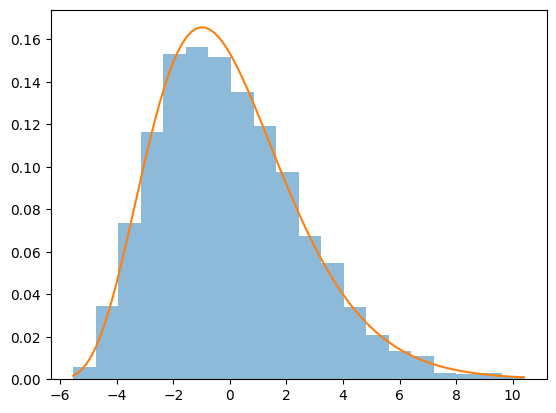

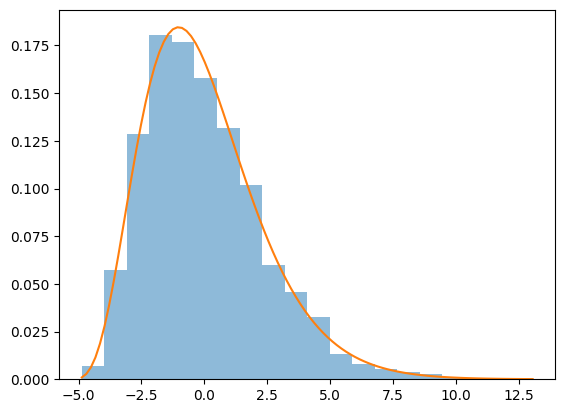

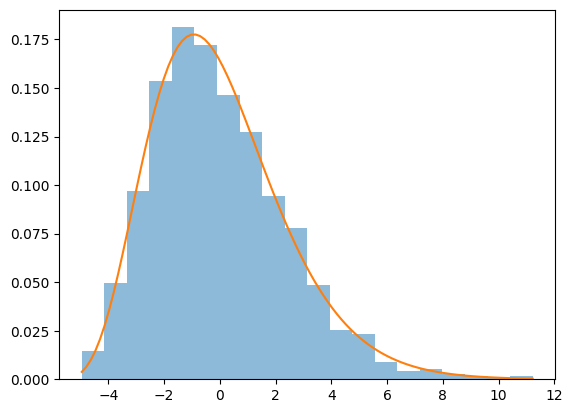

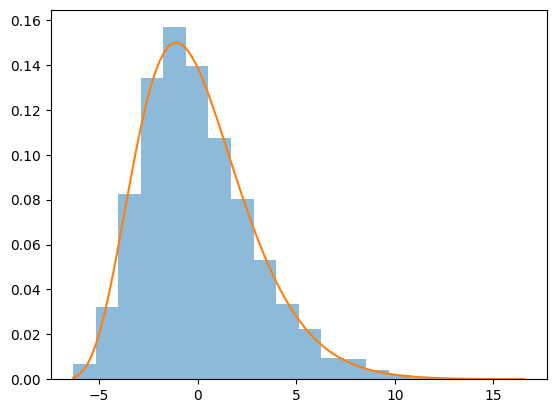

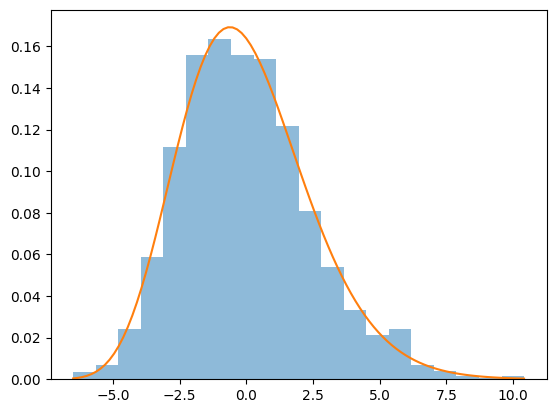

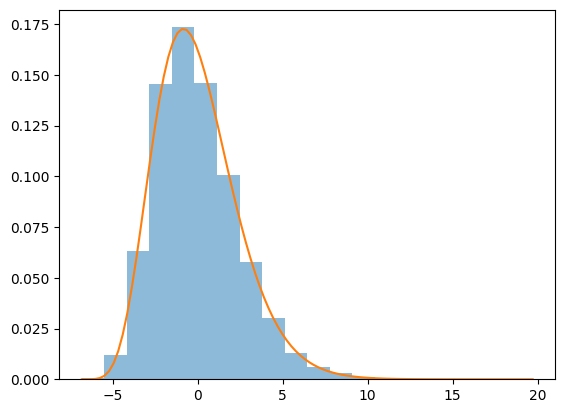

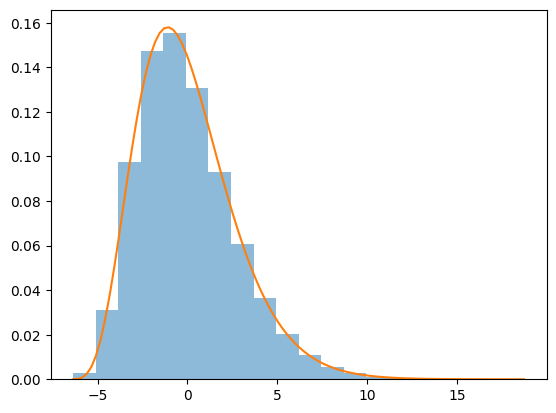

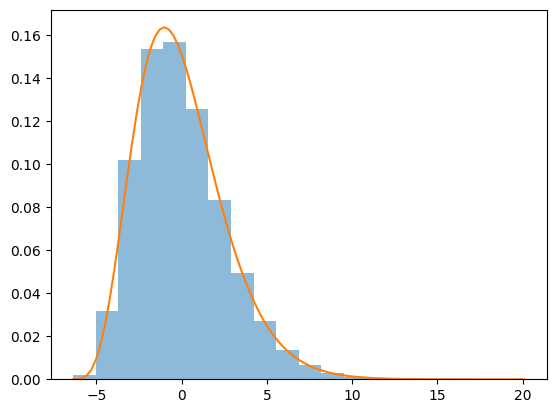

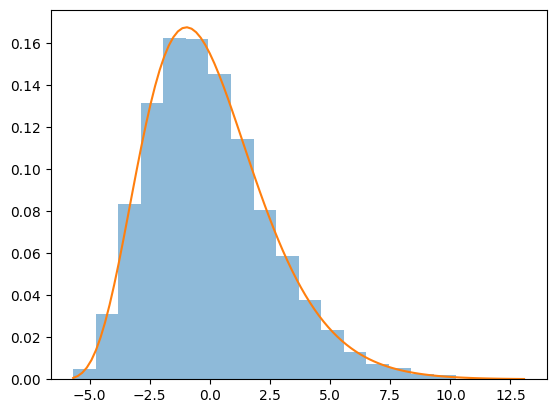

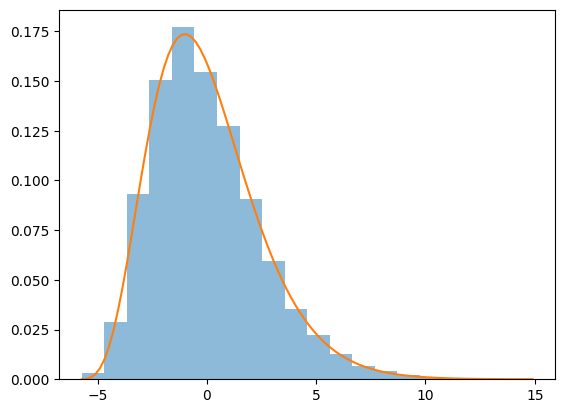

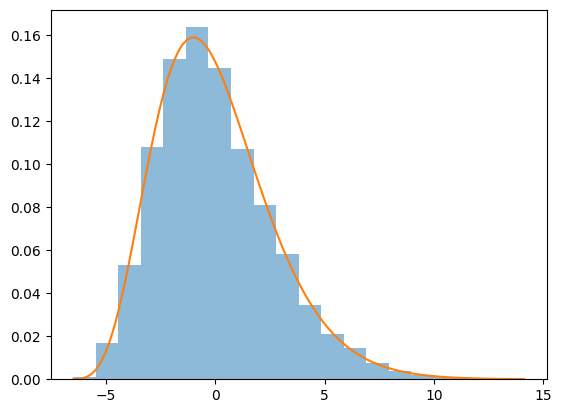

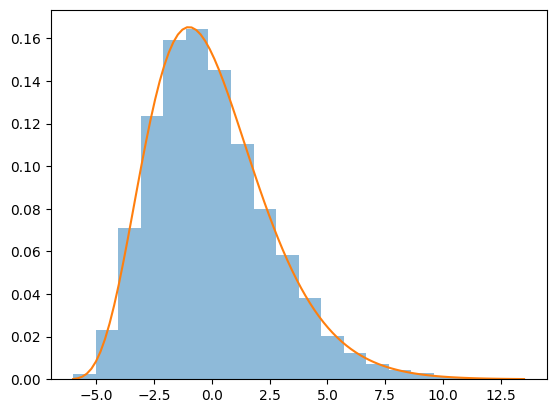

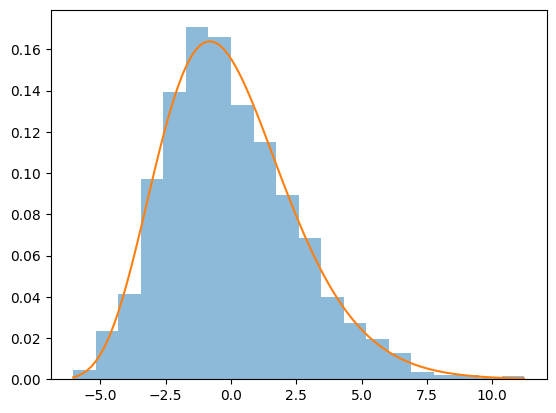

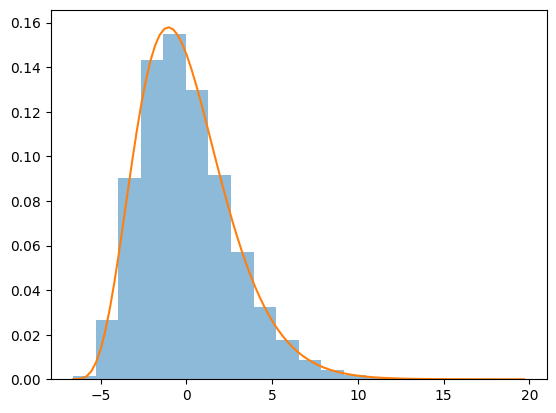

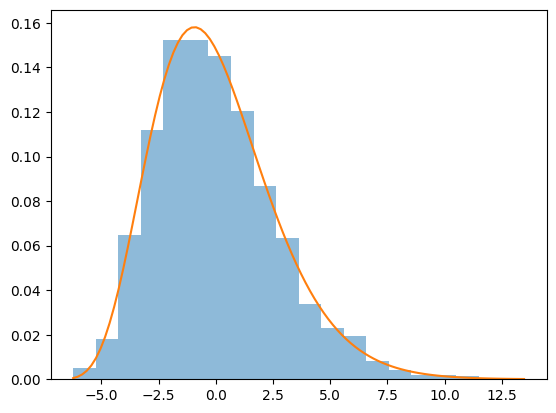

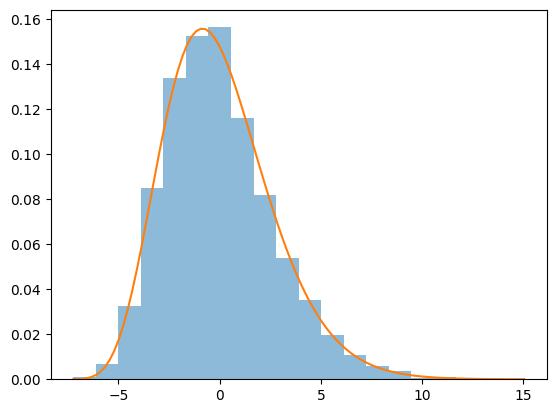

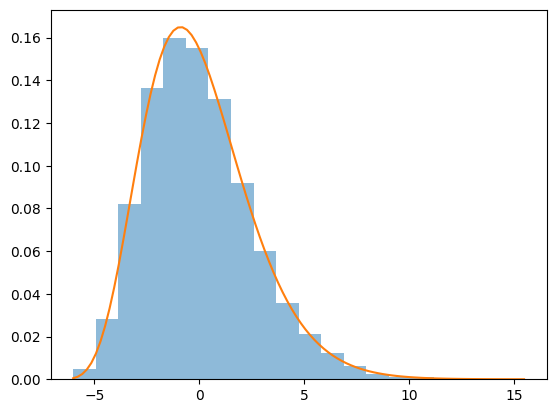

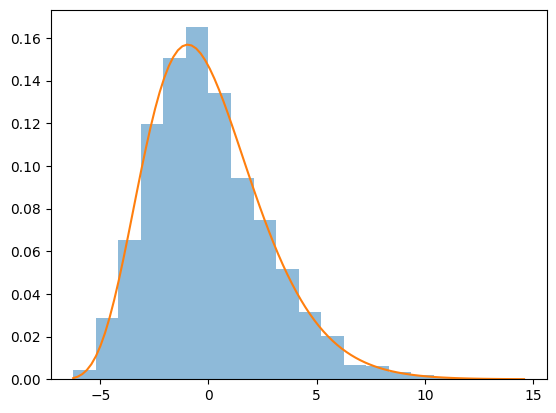

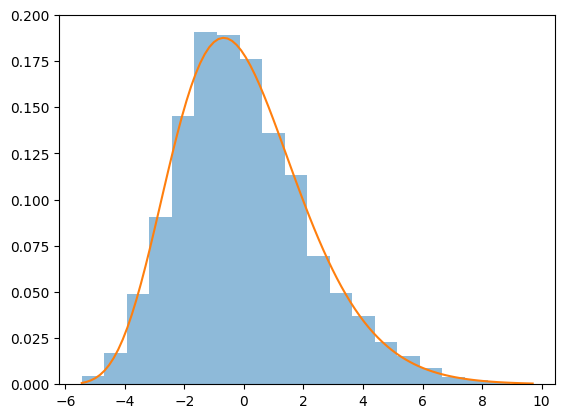

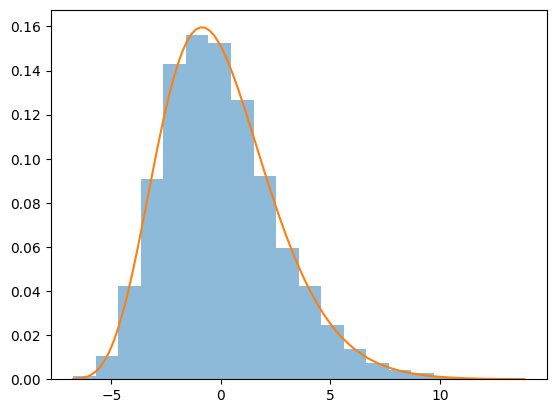

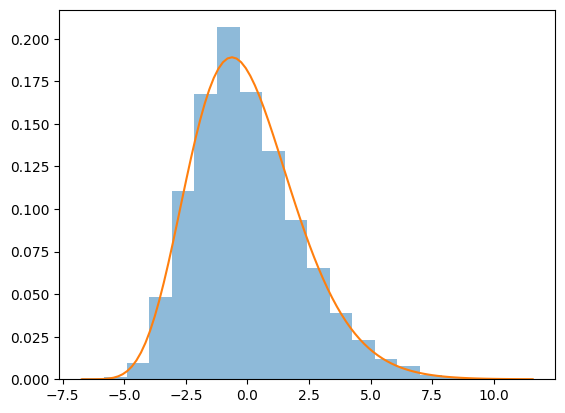

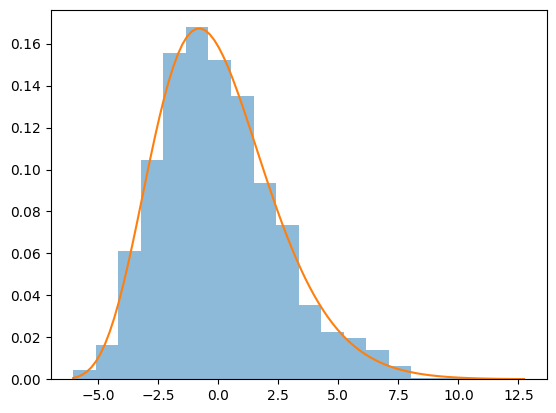

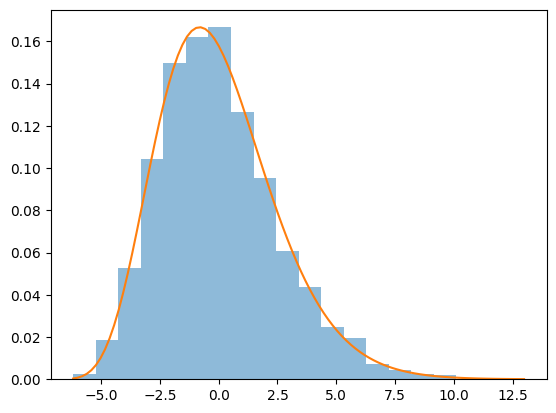

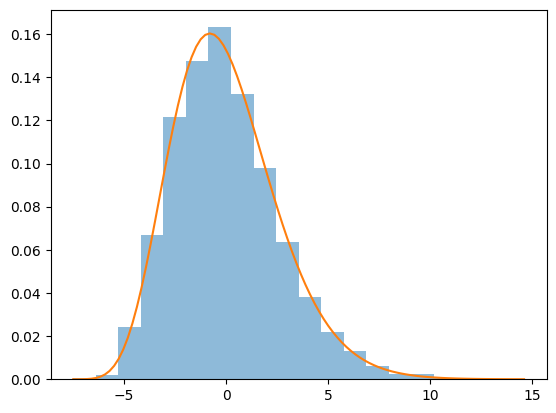

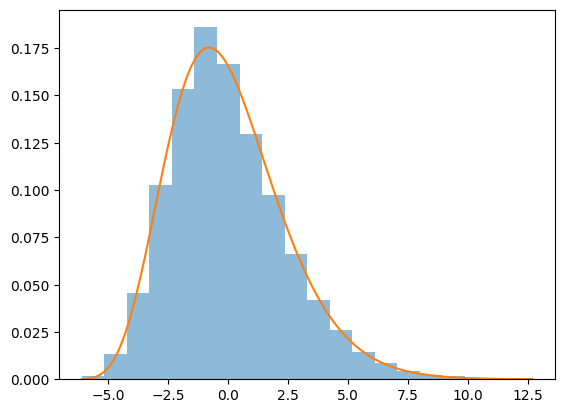

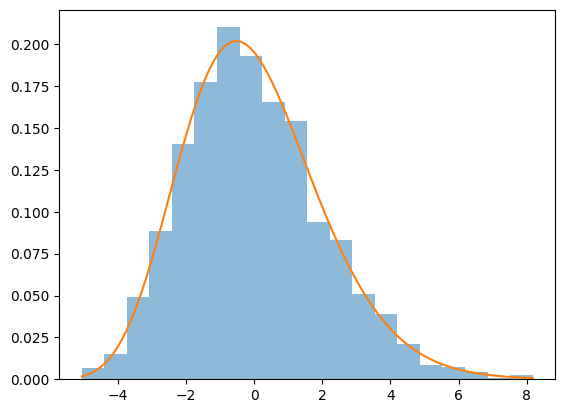

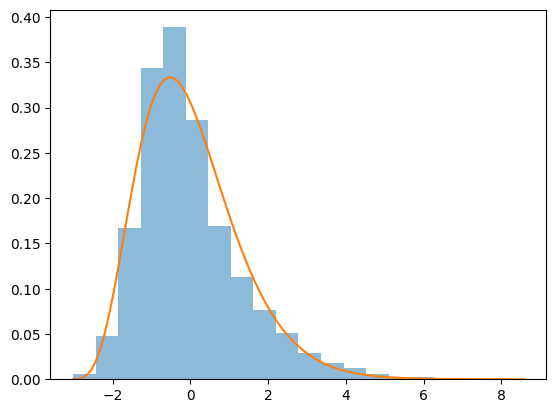

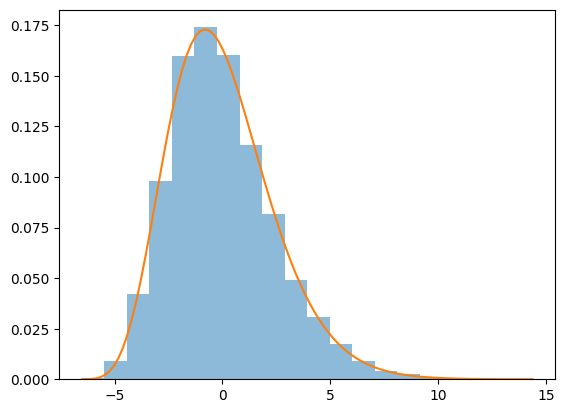

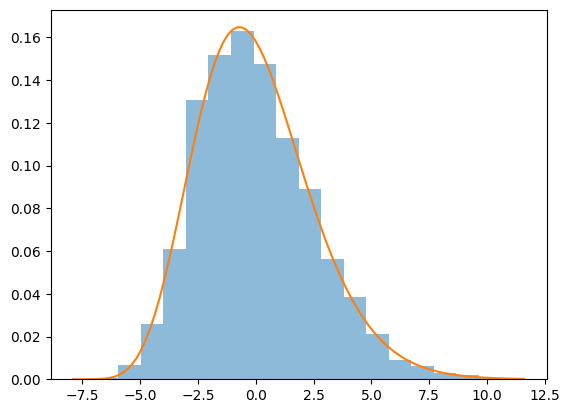

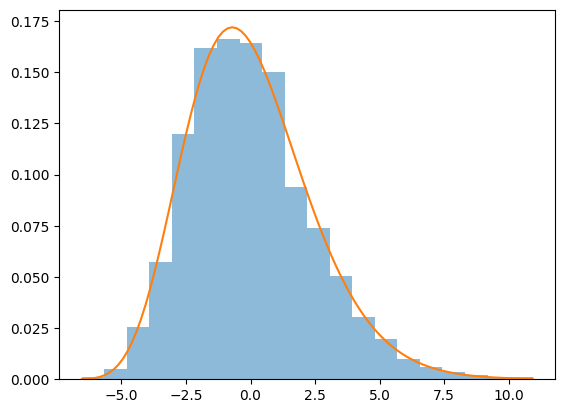

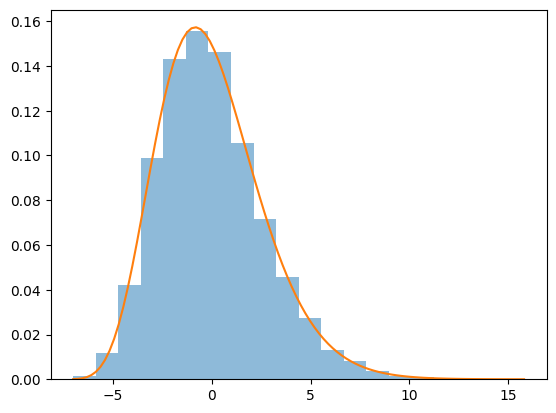

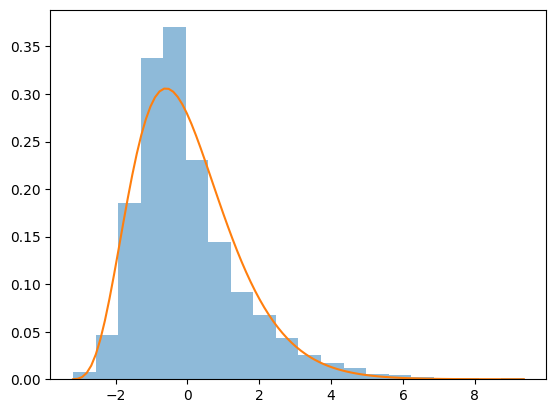

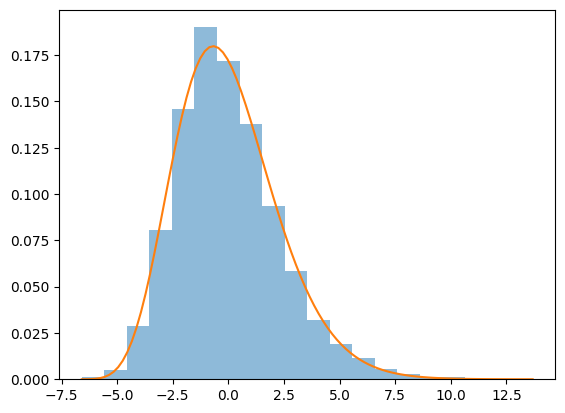

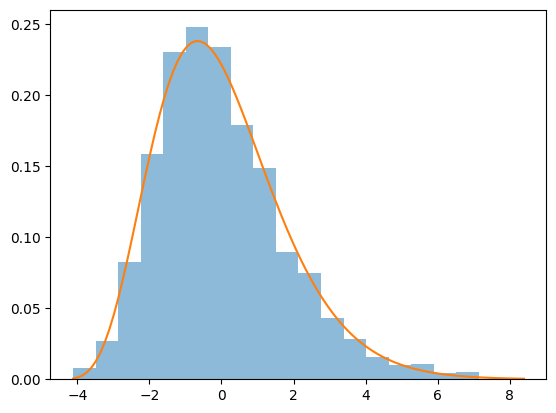

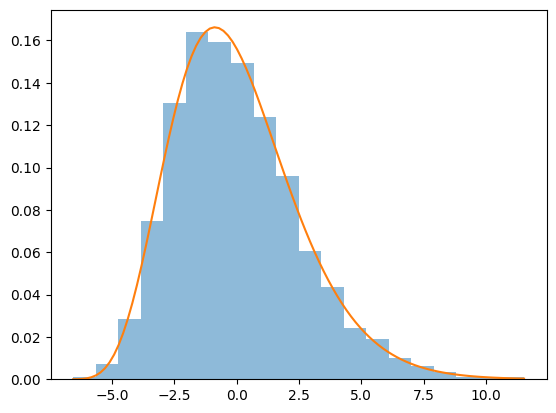

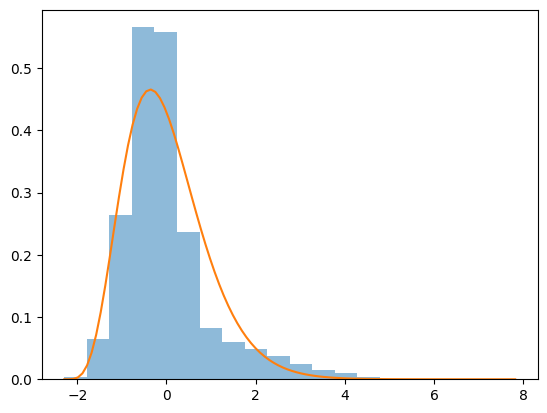

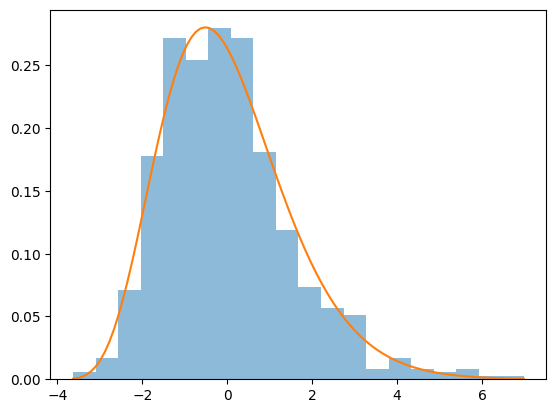

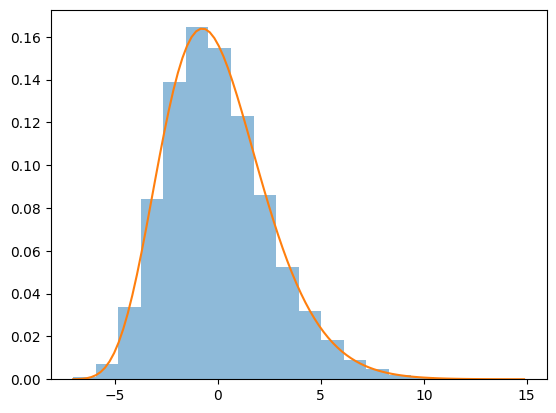

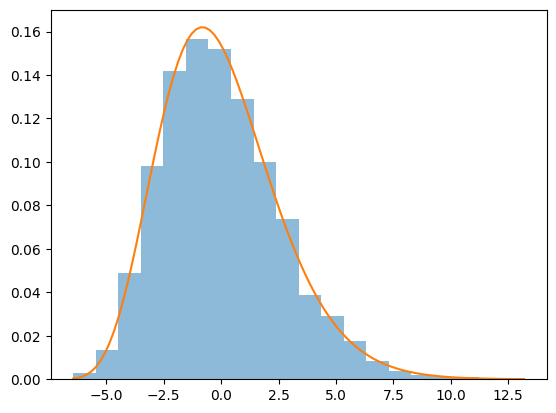

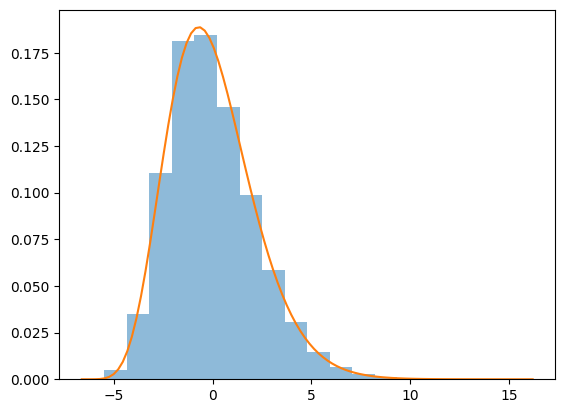

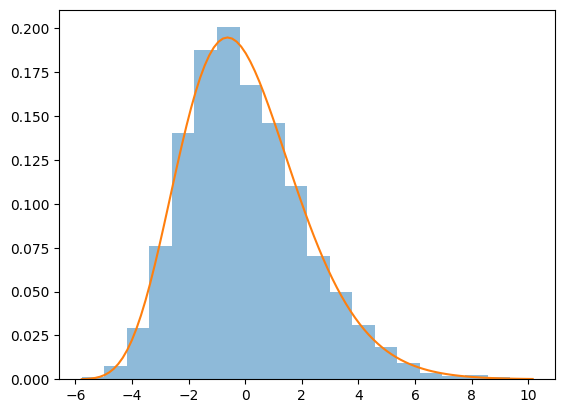

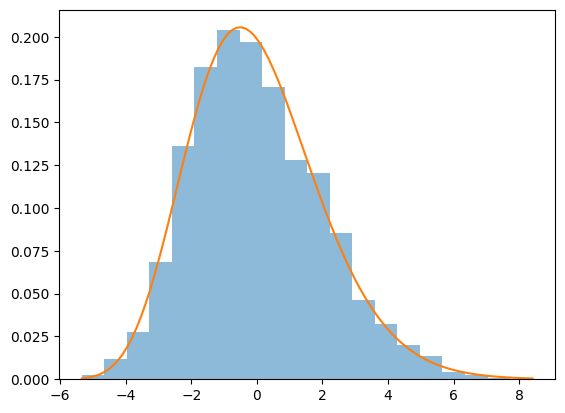

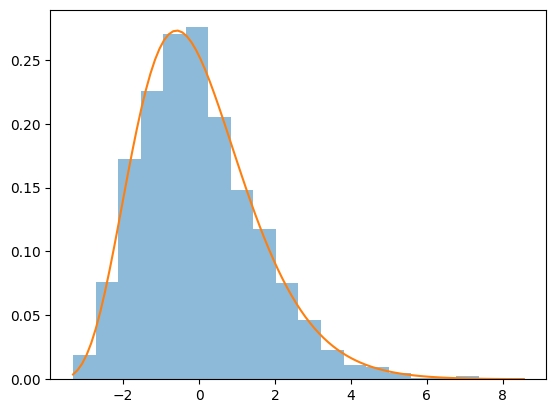

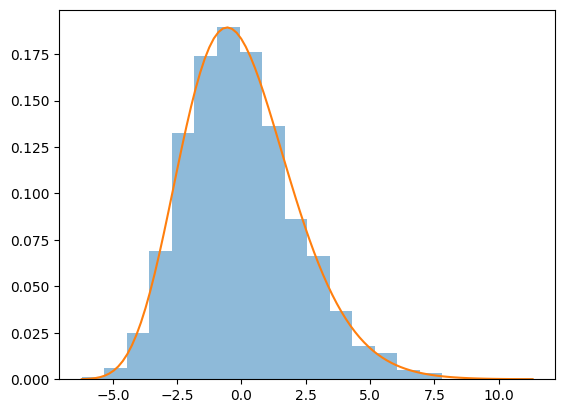

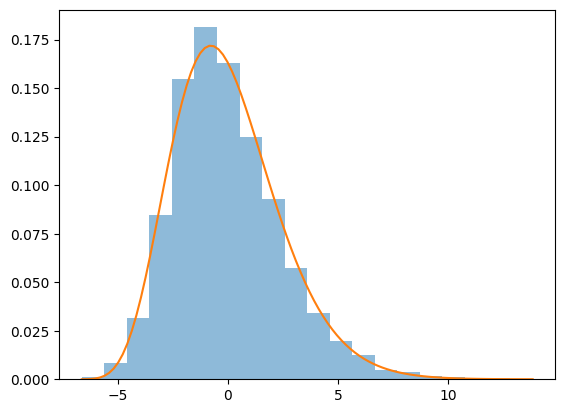

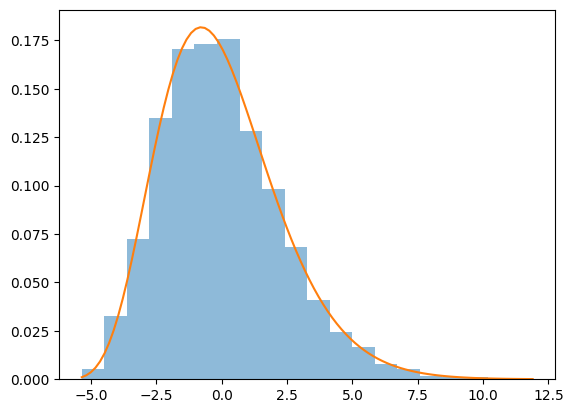

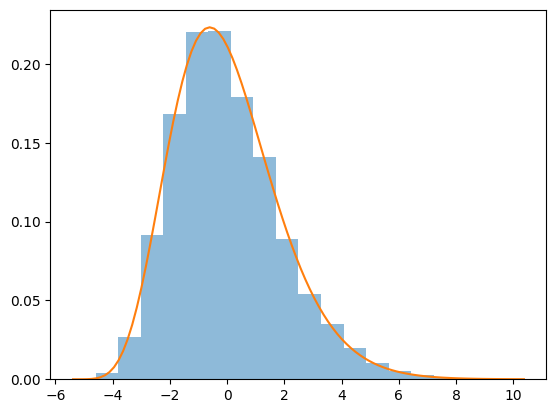

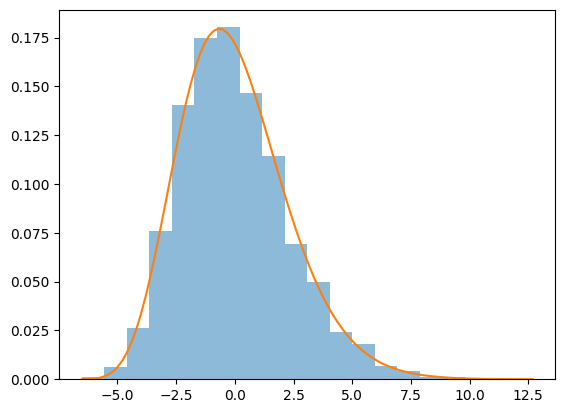

ValueError: need at least one array to concatenate

In [31]:
fit_and_plot_hist("chi2")